# Model 5: Flight arrival delay prediction with a decision tree

### Authors
   * Jonathan Sancho Loaiza
   * Jennifer Lopez Miranda
   * Magdaleno Gomez Diaz

## Problem Analysis (CRISP-DM 1: Business Understanding)

A traveller who asks the assistant "how late will my flight be" wants a number of minutes, and wants it before leaving for the airport. Airlines and airports publish their delays after the fact, so the question is whether the delay of a flight can be predicted from what is known in advance: the airline, the route, the month, the day of the week and the scheduled hour of departure.

The dataset is the airline delay causes file published on Kaggle by giovamata, taken from the United States Bureau of Transportation Statistics for the year 2008. It holds 1.9 million flights and, for each one, the scheduled and real times, the carrier, the origin and destination airports, the distance, the arrival delay in minutes, which is the target, and the departure delay, plus five columns that split the delay into its causes when it exceeds 15 minutes.

The technique is the decision tree, taught in week five, in its regression form. A tree splits the flights by asking one question at a time, such as whether the departure hour is after 17, and predicts for each group the average delay of the training flights that fell in it. The result is a set of rules a person can read, which is the reason to choose it here: the assistant can explain why it expects a delay, not only how many minutes.

The notebook has a second purpose, which is to show the difference between a model that looks accurate and a model that is useful. Several columns of the file describe the delay itself, and a model that reads them predicts the arrival delay almost perfectly while answering nothing the traveller can use. That model is built first, because it is the literal reading of the task, and the honest model is built after it.

### Libraries

In [1]:
# Dataset handling
import os
import kagglehub
import numpy as np
import pandas as pd

# Plots
import matplotlib.pyplot as plt
import seaborn as sns

# Model
from sklearn.tree import DecisionTreeRegressor, plot_tree

# Split, validation, evaluation and persistence
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import joblib

%matplotlib inline

RANDOM_STATE = 42

# Folder shared by every model of the project, read later by the REST API
MODELS_DIR = os.path.join('..', 'models')
os.makedirs(MODELS_DIR, exist_ok=True)

/home/jony/ai-project/env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data Understanding (CRISP-DM 2)

The dataset is downloaded through kagglehub, which caches it locally and returns the folder, so the cell works unchanged on a local machine and in Google Colab. The file is 250 MB and takes a few seconds to read.

In [2]:
path = kagglehub.dataset_download('giovamata/airlinedelaycauses')
print('Path to dataset files:', path)
flights = pd.read_csv(os.path.join(path, 'DelayedFlights.csv'), low_memory=False)
flights.head()

Path to dataset files: /home/jony/.cache/kagglehub/datasets/giovamata/airlinedelaycauses/versions/2


,Unnamed: 0,Year,Month,DayofMonth,DayOfWeek,DepTime,CRSDepTime,ArrTime,CRSArrTime,UniqueCarrier,...,TaxiIn,TaxiOut,Cancelled,CancellationCode,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,0,2008,1,3,4,2003.0,1955,2211.0,2225,WN,...,4.0,8.0,0,N,0,NaN,NaN,NaN,NaN,NaN
1,1,2008,1,3,4,754.0,735,1002.0,1000,WN,...,5.0,10.0,0,N,0,NaN,NaN,NaN,NaN,NaN
2,2,2008,1,3,4,628.0,620,804.0,750,WN,...,3.0,17.0,0,N,0,NaN,NaN,NaN,NaN,NaN
3,4,2008,1,3,4,1829.0,1755,1959.0,1925,WN,...,3.0,10.0,0,N,0,2.0,0.0,0.0,0.0,32.0
4,5,2008,1,3,4,1940.0,1915,2121.0,2110,WN,...,4.0,10.0,0,N,0,NaN,NaN,NaN,NaN,NaN


Each row is one flight. `Year`, `Month`, `DayofMonth` and `DayOfWeek` give the date, `CRSDepTime` and `CRSArrTime` the scheduled times as hour and minute digits, so 1955 means 19:55, and `DepTime` and `ArrTime` the real ones. `UniqueCarrier` is the airline code, `Origin` and `Dest` the airports, `Distance` is in miles. `ArrDelay` is the target, the arrival delay in minutes, and `DepDelay` the departure delay. `TaxiIn` and `TaxiOut` are the minutes on the ground between the gate and the runway. The last five columns split a delay into its causes. The first column, `Unnamed: 0`, is a leftover row number.

In [3]:
print("Rows and columns:", flights.shape)
flights.info()

Rows and columns: (1936758, 30)
<class 'pandas.DataFrame'>
RangeIndex: 1936758 entries, 0 to 1936757
Data columns (total 30 columns):
 #   Column             Dtype  
---  ------             -----  
 0   Unnamed: 0         int64  
 1   Year               int64  
 2   Month              int64  
 3   DayofMonth         int64  
 4   DayOfWeek          int64  
 5   DepTime            float64
 6   CRSDepTime         int64  
 7   ArrTime            float64
 8   CRSArrTime         int64  
 9   UniqueCarrier      str    
 10  FlightNum          int64  
 11  TailNum            str    
 12  ActualElapsedTime  float64
 13  CRSElapsedTime     float64
 14  AirTime            float64
 15  ArrDelay           float64
 16  DepDelay           float64
 17  Origin             str    
 18  Dest               str    
 19  Distance           int64  
 20  TaxiIn             float64
 21  TaxiOut            float64
 22  Cancelled          int64  
 23  CancellationCode   str    
 24  Diverted           int64  
 2

There are 1,936,758 flights and 30 columns. `ArrDelay` has 1,928,371 non null values, so about 8,400 flights have no arrival delay recorded, and the five cause columns have 1,247,488, so a third of the flights have no cause breakdown. Those gaps are explained in the next cells.

In [4]:
print("Cancelled flights:", int(flights['Cancelled'].sum()))
print("Diverted flights:", int(flights['Diverted'].sum()))
print("Flights without an arrival delay:", int(flights['ArrDelay'].isna().sum()))
print()
print(flights[['ArrDelay', 'DepDelay']].describe().round(1))

Cancelled flights: 633
Diverted flights: 7754
Flights without an arrival delay: 8387

        ArrDelay   DepDelay
count  1928371.0  1936758.0
mean        42.2       43.2
std         56.8       53.4
min       -109.0        6.0
25%          9.0       12.0
50%         24.0       24.0
75%         56.0       53.0
max       2461.0     2467.0


The 633 cancelled and 7,754 diverted flights never arrived at their destination, which is why their arrival delay is empty, and they are removed in the preparation. The summary of the two delays reveals what this file is. The minimum departure delay is 6 minutes, not a negative number, and the median arrival delay is 24 minutes: this is not every flight of 2008 but the flights that left late. The file was built from the delayed flights only, so the question the model can answer is not whether a flight will be late but how late a late flight will arrive. That changes the reading of every number below, and the results section comes back to it.

Both delays have a mean near 43 minutes, a median of 24 and a maximum above 2,400 minutes, which is a flight that arrived a day and a half late. A mean well above the median means a long tail of very late flights.

In [5]:
# Keep the flights that arrived, and take a random sample of the file
flights = flights[(flights['Cancelled'] == 0) & (flights['Diverted'] == 0) & flights['ArrDelay'].notna()]
print("Flights that arrived:", len(flights))

SAMPLE_SIZE = 200000
flights = flights.sample(SAMPLE_SIZE, random_state=RANDOM_STATE).reset_index(drop=True)
print("Flights in the working sample:", len(flights))

Flights that arrived: 1928371
Flights in the working sample: 200000


After removing the flights that never arrived, 1,928,371 remain. The notebook works on a random sample of 200,000 of them, drawn with a fixed seed. A decision tree on two million rows with cross-validation over a dozen depths takes long enough to make the notebook hard to rerun, and a sample of this size still holds every airline, every month and almost every airport many times over, so nothing in the analysis depends on the rows left out.

count    200000.0
mean         42.2
std          57.0
min         -59.0
25%           9.0
50%          24.0
75%          56.0
max        1525.0
Name: ArrDelay, dtype: float64
Imbalance (skew), 0 is symmetric and positive means a long right tail: 3.96
Share of flights that arrived early or on time: 10.5 %
Share of flights with a delay of 60 minutes or more: 23.2 %


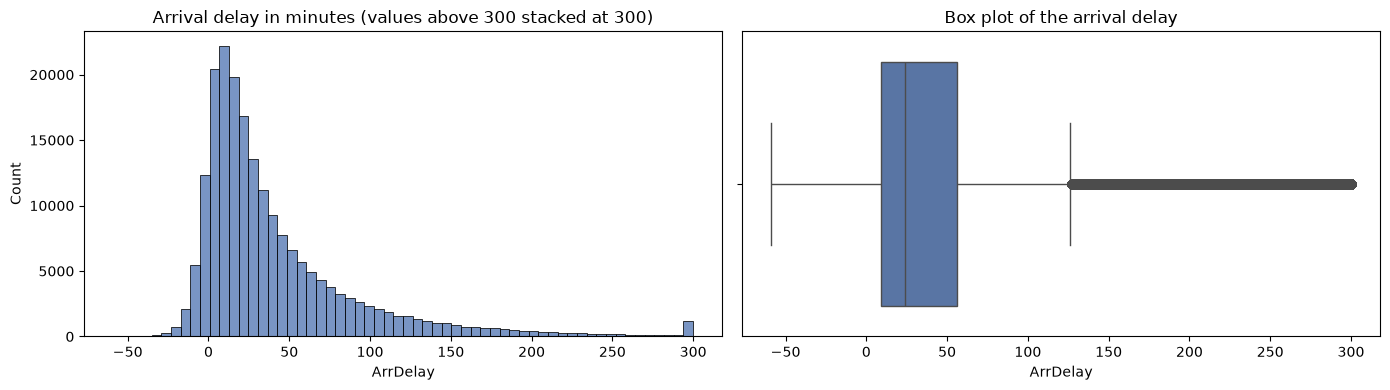

In [6]:
# The target: distribution and how much of it is a large delay
print(flights['ArrDelay'].describe().round(1))
print("Imbalance (skew), 0 is symmetric and positive means a long right tail:", round(flights['ArrDelay'].skew(), 2))
print("Share of flights that arrived early or on time:", round((flights['ArrDelay'] <= 0).mean() * 100, 1), "%")
print("Share of flights with a delay of 60 minutes or more:", round((flights['ArrDelay'] >= 60).mean() * 100, 1), "%")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(flights['ArrDelay'].clip(upper=300), bins=60, ax=axes[0], color='#4c72b0')
axes[0].set_title('Arrival delay in minutes (values above 300 stacked at 300)')
sns.boxplot(x=flights['ArrDelay'].clip(upper=300), ax=axes[1], color='#4c72b0')
axes[1].set_title('Box plot of the arrival delay')
plt.tight_layout()
plt.show()

The histogram counts flights per band of delay and is cut at 300 minutes so the shape is visible, with everything beyond stacked in the last bar. The mass sits between 0 and 60 minutes and a thin tail runs to the right, and the skew of 3.9 confirms a strongly unbalanced target. About one flight in ten of this file arrived on time despite leaving late, having recovered the delay in the air, and about a quarter arrived an hour or more late. The box plot puts the middle half of the flights between 9 and 56 minutes and shows a dense line of dots beyond the upper whisker, the very late flights that will dominate the squared error of any model.

## Data Exploration (CRISP-DM 2) and Data Preparation (CRISP-DM 3)

The exploration separates the columns into two groups: those known before the flight, which a traveller can give the assistant the day before, and those known only after the plane has left, which describe the delay rather than predict it.

In [7]:
# The five cause columns add up to the arrival delay whenever it reaches 15 minutes
CAUSES = ['CarrierDelay', 'WeatherDelay', 'NASDelay', 'SecurityDelay', 'LateAircraftDelay']
DELAY_REPORTING_MINUTES = 15
with_causes = flights[flights['ArrDelay'] >= DELAY_REPORTING_MINUTES]
matches = np.isclose(with_causes[CAUSES].sum(axis=1), with_causes['ArrDelay']).mean()
print("Share of delayed flights whose five causes sum exactly to the arrival delay:", round(matches * 100, 1), "%")
print("Share of flights with the causes missing:", round(flights['CarrierDelay'].isna().mean() * 100, 1), "%")

Share of delayed flights whose five causes sum exactly to the arrival delay: 100.0 %
Share of flights with the causes missing: 35.3 %


For every flight delayed 15 minutes or more, the five cause columns add up exactly to the arrival delay, 100 percent of the time. They are the delay, written as an accounting of who was responsible for it after the fact, and they are missing for the 35 percent of flights under 15 minutes because the airline does not have to report causes below that. A model that reads them is a calculator. They are excluded from both models.

                Pearson  Spearman
DepDelay          0.953     0.855
TaxiOut           0.286     0.279
TaxiIn            0.158     0.141
DepHour           0.044     0.081
DayOfWeek         0.005    -0.000
DayofMonth        0.002    -0.003
Month            -0.001    -0.012
CRSElapsedTime   -0.017    -0.048
Distance         -0.032    -0.067


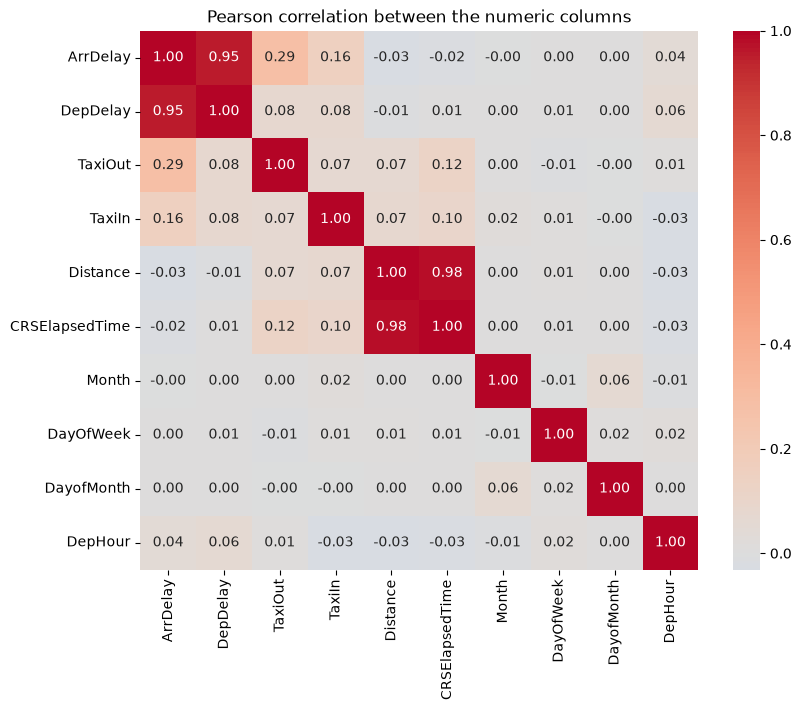

In [8]:
# Scheduled departure hour, taken from the hour and minute digits of CRSDepTime
MINUTES_DIGITS = 100
flights['DepHour'] = flights['CRSDepTime'] // MINUTES_DIGITS

# Correlation of the numeric columns with the arrival delay
numeric = ['ArrDelay', 'DepDelay', 'TaxiOut', 'TaxiIn', 'Distance', 'CRSElapsedTime',
           'Month', 'DayOfWeek', 'DayofMonth', 'DepHour']
correlation = pd.DataFrame({
    'Pearson': flights[numeric].corr()['ArrDelay'],
    'Spearman': flights[numeric].corr(method='spearman')['ArrDelay'],
}).drop('ArrDelay').sort_values('Pearson', ascending=False).round(3)
print(correlation)

plt.figure(figsize=(9, 7))
sns.heatmap(flights[numeric].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Pearson correlation between the numeric columns')
plt.show()

Pearson measures how close a relationship is to a straight line and Spearman whether the ranking of one column follows the other, both from -1 to 1. The heatmap colours the same numbers, red for pairs that rise together and blue for pairs that move apart.

`DepDelay` correlates at 0.95 with the arrival delay in Pearson and 0.86 in Spearman. A plane that leaves 40 minutes late arrives about 40 minutes late, and the difference between the two is a few minutes of taxi time and whatever the crew recovers in the air. `TaxiOut` follows at 0.29, since a long wait on the runway is itself part of the delay. Both are known only once the plane has left the gate, so they belong to the group that describes the delay. Everything the traveller knows in advance correlates weakly: the departure hour at 0.04, the distance at -0.03, and the month, the day of the week and the day of the month at zero. A correlation of zero does not rule these columns out for a tree, which can find the delay rising in the evening hours or in December without the relationship being a straight line, but it sets the expectation for how much they will explain.

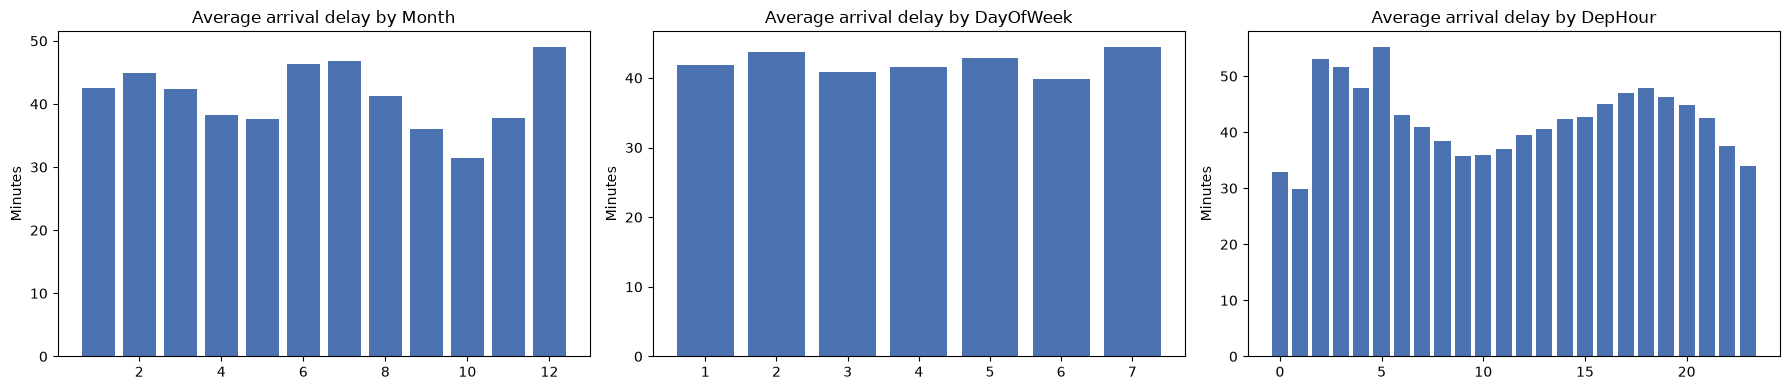

Month     1     2     3     4     5     6     7     8     9     10    11    12
mean    42.6  44.9  42.4  38.3  37.5  46.3  46.9  41.3  36.0  31.5  37.8  49.1
median  25.0  28.0  25.0  22.0  22.0  28.0  26.0  23.0  20.0  17.0  21.0  30.0


In [9]:
# Average delay by month, day of the week and scheduled hour
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, column in zip(axes, ['Month', 'DayOfWeek', 'DepHour']):
    grouped = flights.groupby(column)['ArrDelay'].mean()
    ax.bar(grouped.index, grouped.values, color='#4c72b0')
    ax.set_title('Average arrival delay by ' + column)
    ax.set_ylabel('Minutes')
plt.tight_layout()
plt.show()
print(flights.groupby('Month')['ArrDelay'].agg(['mean', 'median']).round(1).T)

Each bar is the average delay, in minutes, of the flights in that month, weekday or scheduled hour. December is the worst month with a mean of 49 minutes, and October the best with 31, a gap of 18 minutes that a tree can use. The days of the week are flat, all between 40 and 45 minutes, so that column carries almost nothing. The scheduled hour has a shape: flights before 9 in the morning average under 40 minutes and the delay climbs through the afternoon to a peak near 48 minutes at 18 hours, because each late departure pushes the next flight of the same plane later. The few flights scheduled between 2 and 5 in the morning have high averages but rest on ten or twenty flights each.

In [10]:
# Average delay by airline, and the number of airports
by_carrier = flights.groupby('UniqueCarrier')['ArrDelay'].agg(['mean', 'median', 'count']).round(1).sort_values('mean')
print(by_carrier)
print()
print("Origin airports:", flights['Origin'].nunique(), " Destination airports:", flights['Dest'].nunique())

               mean  median  count
UniqueCarrier                     
AQ             24.2    13.0     88
F9             28.8    18.0   2976
WN             29.7    17.0  38951
HA             34.6    18.0    778
US             35.8    21.0  10265
AS             36.5    22.0   4052
DL             39.7    22.0  11931
CO             41.8    22.0  10335
NW             43.1    27.0   8166
FL             43.3    25.0   7355
9E             45.4    28.0   5307
MQ             45.9    28.0  14463
OO             46.1    27.0  13625
AA             46.9    29.0  19731
EV             47.5    28.0   8491
UA             47.6    29.0  14604
XE             50.7    30.0  10819
OH             52.5    33.0   5321
B6             54.4    32.0   5680
YV             55.0    33.0   7062

Origin airports: 298  Destination airports: 299


The airlines span a range of 30 minutes: Southwest, code WN and the largest carrier in the sample with 38,951 flights, averages 30 minutes of arrival delay, while YV and B6 average 55 and 54. The carrier is therefore the most informative fact the traveller can give. There are 298 origin and 299 destination airports, far too many for a tree to read as text, so they need a numeric encoding.

In [11]:
# Encodings. The carrier becomes an integer code, and each airport is replaced by
# how many flights of the sample use it, so a big hub and a small field differ
carrier_encoding = {code: i for i, code in enumerate(sorted(flights['UniqueCarrier'].unique()))}
flights['Carrier_code'] = flights['UniqueCarrier'].map(carrier_encoding)

airport_encoding = flights['Origin'].value_counts().to_dict()
flights['Origin_freq'] = flights['Origin'].map(airport_encoding)
flights['Dest_freq'] = flights['Dest'].map(flights['Dest'].value_counts().to_dict())

TARGET = 'ArrDelay'
SCHEDULE_FEATURES = ['Month', 'DayOfWeek', 'DayofMonth', 'DepHour', 'Carrier_code', 'Distance', 'Origin_freq', 'Dest_freq']
LITERAL_FEATURES = ['DepDelay', 'TaxiOut'] + SCHEDULE_FEATURES

flights_train, flights_test = train_test_split(flights, test_size=0.25, random_state=RANDOM_STATE)
print("Training flights:", len(flights_train))
print("Test flights:", len(flights_test))

Training flights: 150000
Test flights: 50000


The carrier code is an integer from 0 to 19 in alphabetical order, which a tree handles by splitting the list wherever the delay changes, and each airport is replaced by its number of flights in the sample, so the model can tell a hub from a regional field without one column per airport. Neither encoding looks at the target, so nothing about the delay leaks into the predictors. The schedule features are the eight facts known in advance, and the literal set adds the two facts known only after departure. The split leaves 150,000 flights for training and 50,000 for testing.

## Machine Learning Model (CRISP-DM 4: Modeling)

Model A is the literal model: a decision tree that reads everything except the five cause columns, including the departure delay. Model B is the honest one and reads only the schedule. The depth of a tree is the number of questions it asks before predicting, and a tree left to grow without a limit memorises the training flights, so both are limited in depth and Model B's depth is chosen by cross-validation.

### Model A: literal, with the departure delay

In [12]:
LITERAL_DEPTH = 8
model_literal = DecisionTreeRegressor(max_depth=LITERAL_DEPTH, random_state=RANDOM_STATE)
model_literal.fit(flights_train[LITERAL_FEATURES], flights_train[TARGET])

# Which columns the tree actually used, as the share of the error each one removed
importance_literal = pd.Series(model_literal.feature_importances_, index=LITERAL_FEATURES).sort_values(ascending=False)
print(importance_literal.round(3))

DepDelay        0.949
TaxiOut         0.049
Origin_freq     0.001
Distance        0.000
DepHour         0.000
Dest_freq       0.000
DayofMonth      0.000
Month           0.000
DayOfWeek       0.000
Carrier_code    0.000
dtype: float64


The importance of a column is the share of the total reduction in error that its splits produced, summing to 1 over all columns. The departure delay takes 0.95 of it and the taxi out time 0.05, and the eight schedule columns together take less than 0.002. The tree found that once the departure delay is known, nothing else is worth asking about.

In [13]:
def evaluate(model, features, name):
    predicted = model.predict(flights_test[features])
    actual = flights_test[TARGET]
    return pd.Series({
        'R2': r2_score(actual, predicted),
        'MAE (minutes)': mean_absolute_error(actual, predicted),
        'RMSE (minutes)': np.sqrt(mean_squared_error(actual, predicted)),
    }, name=name)

metrics_literal = evaluate(model_literal, LITERAL_FEATURES, 'Model A: with DepDelay')
print(metrics_literal.round(3))

# The trivial rule the tree is imitating: arrival delay equals departure delay
copy_rule = pd.Series({
    'R2': r2_score(flights_test[TARGET], flights_test['DepDelay']),
    'MAE (minutes)': mean_absolute_error(flights_test[TARGET], flights_test['DepDelay']),
    'RMSE (minutes)': np.sqrt(mean_squared_error(flights_test[TARGET], flights_test['DepDelay'])),
}, name='Rule: ArrDelay = DepDelay')
print()
print(copy_rule.round(3))

R2                 0.952
MAE (minutes)      8.932
RMSE (minutes)    12.683
Name: Model A: with DepDelay, dtype: float64

R2                 0.91
MAE (minutes)     11.51
RMSE (minutes)    17.38
Name: Rule: ArrDelay = DepDelay, dtype: float64


R-squared is the share of the variation of the delay that the model explains, from 0 to 1, the mean absolute error is the average miss in minutes and the root mean squared error weighs the large misses more. Model A reaches an R-squared of 0.95 on the test flights with an average miss of 9 minutes, and the rule that simply repeats the departure delay reaches 0.91 with a miss of 11.5 minutes. The tree improves on the copy rule by about two and a half minutes, which is the taxi time it learned to add.

This is the accurate but useless model. Its answer to "how late will my flight arrive" is "about as late as it departs", and it can only give that answer once the plane has already left the gate, when the traveller is inside it. The question of the project is asked the day before, so Model A does not answer it.

### Model B: honest, schedule only

3     0.0212
4     0.0263
5     0.0306
6     0.0352
7     0.0391
8     0.0404
9     0.0417
10    0.0410
11    0.0408
12    0.0396
13    0.0383
14    0.0361
15    0.0343
dtype: float64
Best depth: 9


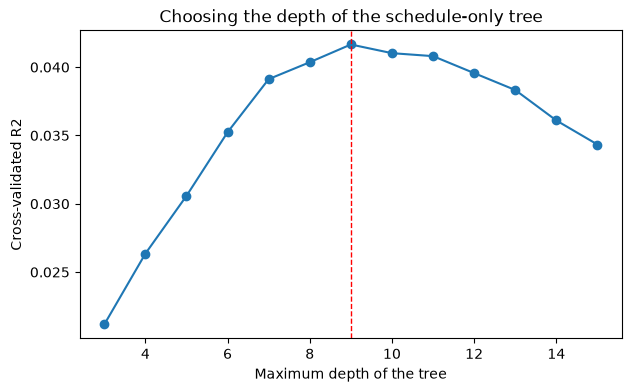

In [14]:
# Choose the depth by 3-fold cross-validation on the training flights. Each fold
# fits the tree on two thirds and scores it on the remaining third
DEPTHS = list(range(3, 16))
MIN_LEAF = 50
folds = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
cv_scores = {}
for depth in DEPTHS:
    tree = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=MIN_LEAF, random_state=RANDOM_STATE)
    cv_scores[depth] = cross_val_score(tree, flights_train[SCHEDULE_FEATURES], flights_train[TARGET],
                                       cv=folds, scoring='r2').mean()
cv_scores = pd.Series(cv_scores)
BEST_DEPTH = int(cv_scores.idxmax())
print(cv_scores.round(4))
print("Best depth:", BEST_DEPTH)

plt.figure(figsize=(7, 4))
plt.plot(cv_scores.index, cv_scores.values, marker='o')
plt.axvline(BEST_DEPTH, color='red', linestyle='--', linewidth=1)
plt.xlabel('Maximum depth of the tree')
plt.ylabel('Cross-validated R2')
plt.title('Choosing the depth of the schedule-only tree')
plt.show()

The curve is the cross-validated R-squared at each depth, that is, the score on flights the tree did not see, averaged over the three folds. It rises from 0.021 at depth 3 to a peak of 0.042 at depth 9 and then falls slowly, because a deeper tree starts to memorise groups of fifty flights that do not generalise. Depth 9 is kept. The scale of the vertical axis is the finding: the best tree the schedule can produce explains 4 percent of the variation in the delay.

Carrier_code    0.224
Dest_freq       0.196
DayofMonth      0.132
Month           0.124
Origin_freq     0.115
DepHour         0.110
Distance        0.053
DayOfWeek       0.047
dtype: float64


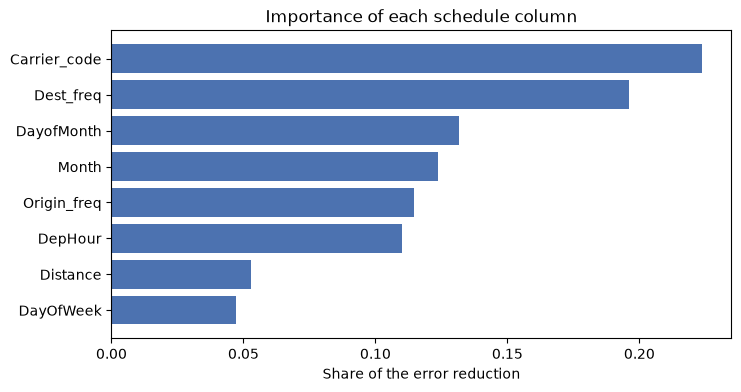

In [15]:
model_schedule = DecisionTreeRegressor(max_depth=BEST_DEPTH, min_samples_leaf=MIN_LEAF, random_state=RANDOM_STATE)
model_schedule.fit(flights_train[SCHEDULE_FEATURES], flights_train[TARGET])

importance_schedule = pd.Series(model_schedule.feature_importances_, index=SCHEDULE_FEATURES).sort_values(ascending=False)
print(importance_schedule.round(3))

plt.figure(figsize=(8, 4))
plt.barh(importance_schedule.index[::-1], importance_schedule.values[::-1], color='#4c72b0')
plt.xlabel('Share of the error reduction')
plt.title('Importance of each schedule column')
plt.show()

Without the departure delay the tree spreads its questions over the schedule. The carrier is the most used column at 0.22, followed by the destination airport at 0.20, the day of the month, the month, the origin and the scheduled hour between 0.11 and 0.13, and the distance and the day of the week close the list at 0.05. This matches the exploration: the carrier had a 30 minute spread between airlines, the month an 18 minute spread, and the weekday almost none.

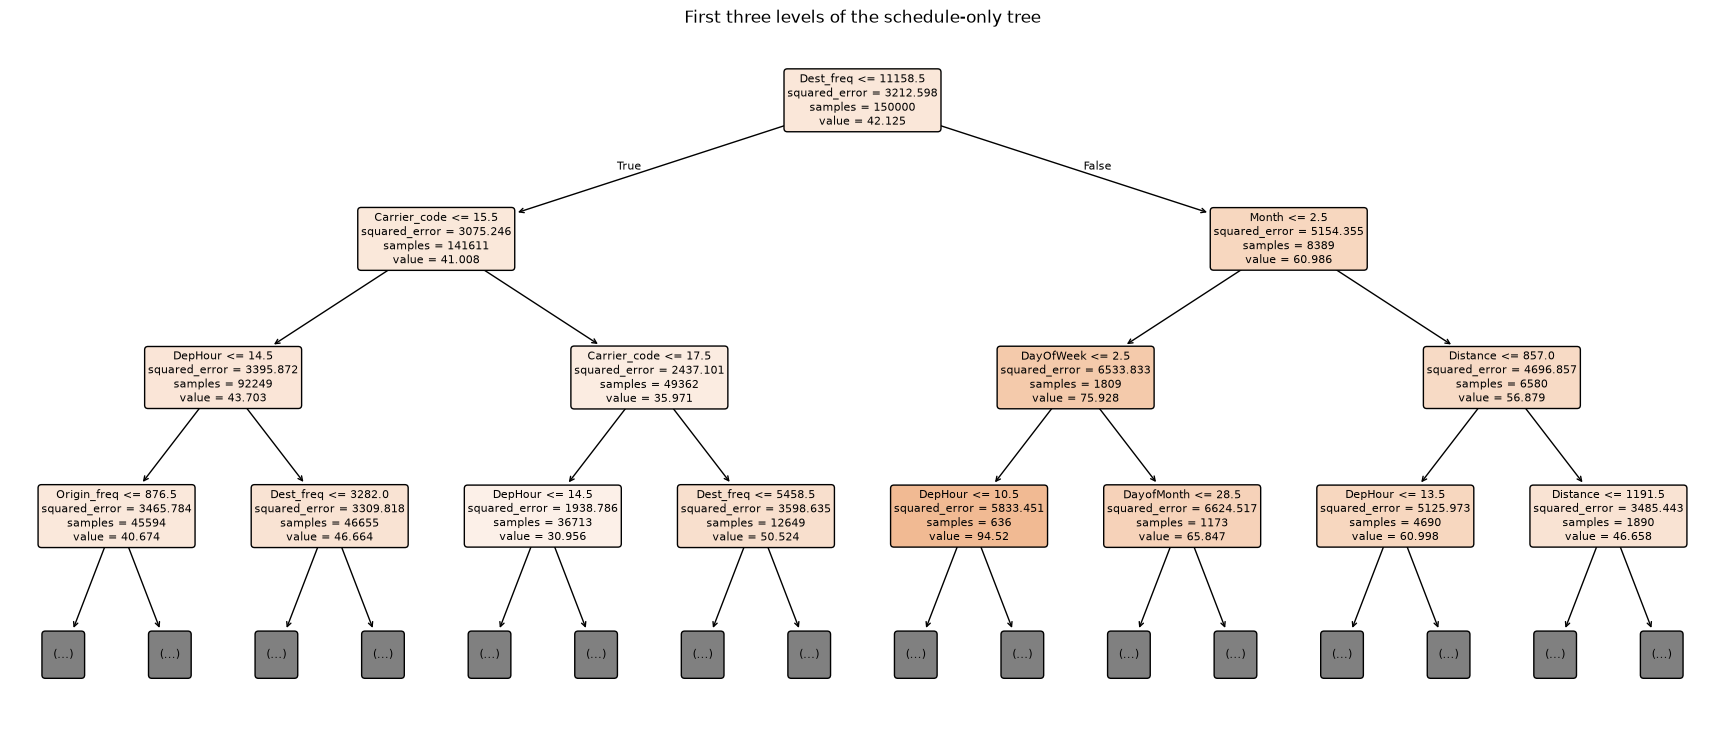

In [16]:
# The first three levels of the tree, drawn
plt.figure(figsize=(22, 9))
plot_tree(model_schedule, max_depth=3, feature_names=SCHEDULE_FEATURES, filled=True, fontsize=8, rounded=True)
plt.title('First three levels of the schedule-only tree')
plt.show()

Each box is a question, and a flight goes left when the answer is yes and right when it is no. `samples` is how many training flights reached the box, `value` is the average delay of those flights, which is what the tree predicts if it stops there, and `squared_error` is the spread of the delays inside the box. The darker the box, the larger its average delay. The root asks whether the destination has more than 11,158 flights in the sample, which singles out one airport, Chicago O'Hare, the busiest destination of the file: the 8,389 training flights bound there average 61 minutes of delay against 41 for everyone else, and among them the flights of January and February average 76. On the larger side the tree asks next about the carrier, with a code above 15.5 grouping US Airways, Southwest, ExpressJet and Mesa, and then about the scheduled hour, splitting the day at 14:30. The values in the boxes move between about 36 and 76 minutes, which is the range of predictions the tree can make near its top: it moves a flight up or down by a quarter of an hour around the average, and nothing in the schedule tells it that a flight will be three hours late.

## Evaluation (CRISP-DM 5)

Both models are scored on the same 50,000 test flights, with the same three metrics, and two trivial rules are added for scale: predicting the average delay of the training flights for every flight, and predicting the median.

In [17]:
metrics_schedule = evaluate(model_schedule, SCHEDULE_FEATURES, 'Model B: schedule only')

def constant_rule(value, name):
    predicted = np.full(len(flights_test), value)
    return pd.Series({
        'R2': r2_score(flights_test[TARGET], predicted),
        'MAE (minutes)': mean_absolute_error(flights_test[TARGET], predicted),
        'RMSE (minutes)': np.sqrt(mean_squared_error(flights_test[TARGET], predicted)),
    }, name=name)

comparison = pd.concat([
    metrics_literal, metrics_schedule,
    constant_rule(flights_train[TARGET].mean(), 'Rule: always the mean'),
    constant_rule(flights_train[TARGET].median(), 'Rule: always the median'),
], axis=1).round(3)
print(comparison)

                Model A: with DepDelay  Model B: schedule only  \
R2                               0.952                   0.050   
MAE (minutes)                    8.932                  35.984   
RMSE (minutes)                  12.683                  56.596   

                Rule: always the mean  Rule: always the median  
R2                             -0.000                   -0.102  
MAE (minutes)                  37.524                   34.268  
RMSE (minutes)                 58.061                   60.952  


Model B reaches an R-squared of 0.050, an average miss of 36.0 minutes and a root mean squared error of 56.6 minutes. Predicting the mean for every flight gives an R-squared of zero by definition and a miss of 37.5 minutes, so the tree improves on it by a minute and a half. Predicting the median gives a miss of 34.3 minutes, better than the tree on that metric, because with a long right tail the median is the constant closest to most flights while the tree, trained to minimise squared error, leans towards the mean. Model A sits at 0.95 and 9 minutes, and the whole distance between the two models is the departure delay, a single column known only after the fact.

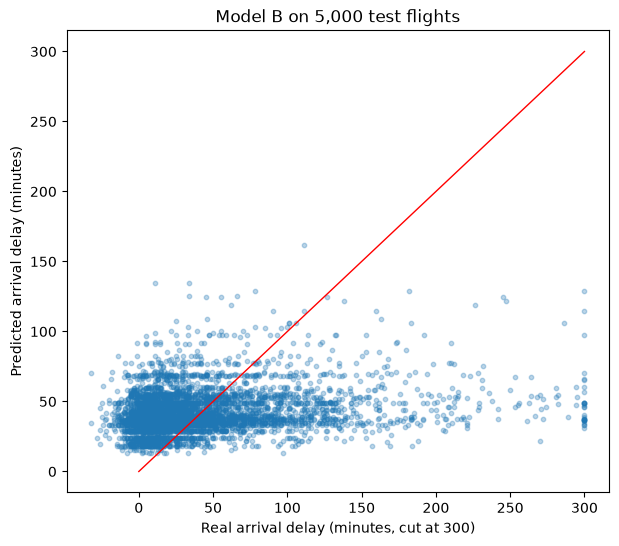

In [18]:
# Real against predicted for the schedule-only tree, on a sample of test flights for readability
PLOT_SIZE = 5000
sample_test = flights_test.sample(PLOT_SIZE, random_state=RANDOM_STATE)
predicted_sample = model_schedule.predict(sample_test[SCHEDULE_FEATURES])

plt.figure(figsize=(7, 6))
plt.scatter(sample_test[TARGET].clip(upper=300), predicted_sample, alpha=0.3, s=10)
plt.plot([0, 300], [0, 300], color='red', linewidth=1)
plt.xlabel('Real arrival delay (minutes, cut at 300)')
plt.ylabel('Predicted arrival delay (minutes)')
plt.title('Model B on 5,000 test flights')
plt.show()

Each dot is a test flight placed by its real delay and its prediction, and the red diagonal is where a perfect prediction would fall. The dots form a horizontal band between roughly 25 and 70 minutes of prediction whatever the real delay is, and the band never approaches the diagonal. This is what an R-squared of 0.050 looks like: the model predicts a slightly higher or lower average for each kind of flight, and the real delay of any single flight is scattered far from that average in both directions.

## Results (CRISP-DM 6: Deployment)

The model kept is Model B, a decision tree of depth 9 that predicts the arrival delay from the airline, the route, the date and the scheduled hour, and on 50,000 test flights it reaches an R-squared of 0.050, a mean absolute error of 36 minutes and a root mean squared error of 57. That is a poor model and the notebook says so. The literal Model A, which also reads the departure delay, reaches 0.95 and 9 minutes, and it was built first and rejected, not because it is inaccurate but because it answers a different question: it converts a known departure delay into an arrival delay, which the traveller can do by adding a few minutes.

The delay is unpredictable from the schedule for a reason the data shows. The causes of a delay are the weather of the day, a mechanical problem, a late inbound aircraft and congestion at the airport, and none of those is in the schedule, so the schedule columns move the average by a quarter of an hour between airlines and hours while the flights around each average spread over an hour. The tree finds the pattern that exists, punctual airlines and morning departures, and cannot find the pattern that does not. There is a second limitation specific to this file: it contains only flights that left late, so the model estimates how late a delayed flight will arrive and says nothing about whether a flight will be delayed at all.

The recommendation for the assistant is to use Model B for a rough expectation, of the form "flights of this airline at this hour arrive about 45 minutes late on average", and to state the average error of 36 minutes beside it. The model, the feature list and the two encodings are saved below so the REST API can encode a flight and predict without training.

In [19]:
bundle = {
    'model': model_schedule,
    'features': SCHEDULE_FEATURES,
    'target': TARGET,
    'carrier_encoding': carrier_encoding,
    'airport_encoding': airport_encoding,
    'dest_encoding': flights['Dest'].value_counts().to_dict(),
}
MODEL_PATH = os.path.join(MODELS_DIR, 'flight_delay_regression.joblib')
joblib.dump(bundle, MODEL_PATH, compress=3)
print("Saved to", MODEL_PATH, "(%.1f KB)" % (os.path.getsize(MODEL_PATH) / 1024))

Saved to ../models/flight_delay_regression.joblib (19.6 KB)


In [20]:
# Reload and predict one flight by hand: American Airlines from Chicago to
# Los Angeles, 1,745 miles, a Friday in December at 18:00
loaded = joblib.load(MODEL_PATH)
flight = pd.DataFrame([{
    'Month': 12, 'DayOfWeek': 5, 'DayofMonth': 19, 'DepHour': 18,
    'Carrier_code': loaded['carrier_encoding']['AA'], 'Distance': 1745,
    'Origin_freq': loaded['airport_encoding']['ORD'], 'Dest_freq': loaded['dest_encoding']['LAX'],
}])
print("Predicted arrival delay: %.0f minutes" % loaded['model'].predict(flight[loaded['features']])[0])

Predicted arrival delay: 39 minutes


The reloaded tree predicts 39 minutes for this flight, a little under the 42 minute average of the file. The December evening and the airline pushed it up but the tree's box for a long flight out of O'Hare on that day of the month pulled it down, which is the kind of quarter-hour adjustment the model can make and no more. The API repeats this call: map the carrier and the airports through the stored encodings, build the eight columns and predict.